# Formative 2: Data Merge and Feature Engineering

## 1. Load the data

We load the two spreadsheets. The social profiles file has the platform, engagement score, purchase interest score and review sentiment for each customer. The transactions file has the amount, date, product category and rating for each purchase.

In [1]:
# load the data

import pandas as pd

social = pd.read_excel("data/customer_social_profiles.xlsx")
trans = pd.read_excel("data/customer_transactions.xlsx")

print("Social profiles:", social.shape)
print(social.head())
print()
print("Transactions:", trans.shape)
print(trans.head())

Social profiles: (155, 5)
  customer_id_new social_media_platform  engagement_score  \
0            A178              LinkedIn                74   
1            A190               Twitter                82   
2            A150              Facebook                96   
3            A162               Twitter                89   
4            A197               Twitter                92   

   purchase_interest_score review_sentiment  
0                      4.9         Positive  
1                      4.8          Neutral  
2                      1.6         Positive  
3                      2.6         Positive  
4                      2.3          Neutral  

Transactions: (150, 6)
   customer_id_legacy  transaction_id  purchase_amount purchase_date  \
0                 151            1001              408    2024-01-01   
1                 192            1002              332    2024-01-02   
2                 114            1003              442    2024-01-03   
3                 1

## 2. Check Data Quality

Before merging, we check the data types, missing values and duplicates. Social profiles has 5 exact duplicate rows. Transactions has 10 missing ratings. Both tables repeat some customer IDs, because a customer can appear in several rows.

In [2]:
# check the data quality

print("=== SOCIAL PROFILES ===")
print(social.dtypes)
print("Missing values:")
print(social.isna().sum())
print("Duplicate rows:", social.duplicated().sum())
print("Duplicate customer IDs:", social["customer_id_new"].duplicated().sum())

print()
print("=== TRANSACTIONS ===")
print(trans.dtypes)
print("Missing values:")
print(trans.isna().sum())
print("Duplicate rows:", trans.duplicated().sum())
print("Duplicate customer IDs:", trans["customer_id_legacy"].duplicated().sum())

=== SOCIAL PROFILES ===
customer_id_new             object
social_media_platform       object
engagement_score             int64
purchase_interest_score    float64
review_sentiment            object
dtype: object
Missing values:
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64
Duplicate rows: 5
Duplicate customer IDs: 71

=== TRANSACTIONS ===
customer_id_legacy             int64
transaction_id                 int64
purchase_amount                int64
purchase_date         datetime64[ns]
product_category              object
customer_rating              float64
dtype: object
Missing values:
customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64
Duplicate rows: 0
Duplicate customer IDs: 75


## 3. Remove Duplicate Rows (Social Profiles)

We remove the 5 exact duplicate rows so that no record is counted twice. Social profiles goes from 155 rows to 150.

In [3]:
# remove the duplicate rows in the social profile

print("Before:", social.shape)

social = social.drop_duplicates().reset_index(drop=True)

print("After:", social.shape)
print("Duplicate rows now:", social.duplicated().sum())

Before: (155, 5)
After: (150, 5)
Duplicate rows now: 0


## 4. Fill Missing Customer Ratings (Transactions)

We fill the 10 missing ratings with the median rating, 3.0. The median is a typical value that is not pulled up or down by a few very high or very low ratings.

In [4]:
# handle the missing values in customer_rating values

print("Missing ratings before:", trans["customer_rating"].isna().sum())

median_rating = trans["customer_rating"].median()
print("Median rating used:", median_rating)

trans["customer_rating"] = trans["customer_rating"].fillna(median_rating)

print("Missing ratings after:", trans["customer_rating"].isna().sum())

Missing ratings before: 10
Median rating used: 3.0
Missing ratings after: 0


## 5. Check How the Customer IDs Match

The social profiles use IDs like A178, while the transactions use numbers like 178. All 150 social IDs start with the letter A, and both tables use numbers between 100 and 199. 61 customer IDs appear in both tables. We assume the number inside the social ID is the same customer as the matching transaction ID. Neither file has a name or email to confirm this, so it is the only possible link.

In [5]:
# figure out how the two ID columns match

# 1. Do all social IDs follow the pattern letter + numbers?
print("IDs starting with 'A':", social["customer_id_new"].str.startswith("A").sum(), "out of", len(social))

# 2. Strip the 'A' and turn the rest into a number (stored in a temporary variable)
social_numbers = social["customer_id_new"].str[1:].astype(int)

print("Social ID range:", social_numbers.min(), "to", social_numbers.max())
print("Transaction ID range:", trans["customer_id_legacy"].min(), "to", trans["customer_id_legacy"].max())

# 3. How many IDs appear in both tables?
common = set(social_numbers) & set(trans["customer_id_legacy"])
print("IDs found in both tables:", len(common))
print("Unique IDs in social:", social_numbers.nunique())
print("Unique IDs in transactions:", trans["customer_id_legacy"].nunique())


IDs starting with 'A': 150 out of 150
Social ID range: 100 to 199
Transaction ID range: 100 to 199
IDs found in both tables: 61
Unique IDs in social: 84
Unique IDs in transactions: 75


## 6. Create a Shared Customer ID

We remove the letter A from the social IDs and turn the rest into a number. We copy the transaction IDs into a column with the same name. Both tables now have a customer_id column of the same type, which we use to join them.

In [6]:
# Create a shared ID column in both tables

# social: remove the leading 'A' and convert the rest to a number
social["customer_id"] = social["customer_id_new"].str[1:].astype(int)

# transactions: the legacy ID is already a number, so just copy it
trans["customer_id"] = trans["customer_id_legacy"]

print(social[["customer_id_new", "customer_id"]].head())
print()
print(trans[["customer_id_legacy", "customer_id"]].head())
print()
print("Same data type in both:", social["customer_id"].dtype == trans["customer_id"].dtype)

  customer_id_new  customer_id
0            A178          178
1            A190          190
2            A150          150
3            A162          162
4            A197          197

   customer_id_legacy  customer_id
0                 151          151
1                 192          192
2                 114          114
3                 171          171
4                 160          160

Same data type in both: True


## 7. Reduce Social Profiles to One Row per Customer

The 150 social rows belong to only 84 customers, so some customers have several rows. Joining them directly would multiply the purchase rows. We reduce them to one row per customer: the two scores are averaged, and the platform and sentiment take the customer's most common value.

In [7]:
# Reduce social profiles to one row per customer 

social_customer = social.groupby("customer_id").agg(
    engagement_score=("engagement_score", "mean"),
    purchase_interest_score=("purchase_interest_score", "mean"),
    social_media_platform=("social_media_platform", lambda x: x.mode().iloc[0]),
    review_sentiment=("review_sentiment", lambda x: x.mode().iloc[0]),
).reset_index()

print(social_customer.shape)
print(social_customer.head())
print("Duplicate customer IDs:", social_customer["customer_id"].duplicated().sum())

(84, 5)
   customer_id  engagement_score  purchase_interest_score  \
0          100         77.000000                 4.400000   
1          101         68.000000                 1.000000   
2          102         51.000000                 4.800000   
3          103         64.333333                 2.866667   
4          104         83.000000                 2.933333   

  social_media_platform review_sentiment  
0             Instagram         Negative  
1               Twitter          Neutral  
2              LinkedIn          Neutral  
3             Instagram         Positive  
4               Twitter         Negative  
Duplicate customer IDs: 0


## 8. Merge the Two Tables

We use a left join with the transactions on the left, which keeps all 150 purchases. Each purchase gets its customer's social data. 117 purchases have social data and 33 do not, because those customers have no social profile. The merge is set to stop with an error if any rows were multiplied.

In [8]:
# Merge the 2 tables

merged = trans.merge(social_customer, on="customer_id", how="left", validate="many_to_one")

print("Merged shape:", merged.shape)
print("Rows with social data:", merged["engagement_score"].notna().sum())
print("Rows without social data:", merged["engagement_score"].isna().sum())
print()
print(merged.head())

Merged shape: (150, 11)
Rows with social data: 117
Rows without social data: 33

   customer_id_legacy  transaction_id  purchase_amount purchase_date  \
0                 151            1001              408    2024-01-01   
1                 192            1002              332    2024-01-02   
2                 114            1003              442    2024-01-03   
3                 171            1004              256    2024-01-04   
4                 160            1005               64    2024-01-05   

  product_category  customer_rating  customer_id  engagement_score  \
0           Sports              2.3          151         71.666667   
1      Electronics              4.2          192         60.000000   
2      Electronics              2.1          114         87.000000   
3         Clothing              2.8          171               NaN   
4         Clothing              1.3          160         72.666667   

   purchase_interest_score social_media_platform review_sentiment

## 9. Fill Missing Social Data

33 purchases belong to customers with no social profile. We keep them, because dropping them would remove 22% of the data. The two scores are filled with the median, and the platform and sentiment are labeled "Unknown". We first add a has_social_profile column (1 = yes, 0 = no), so the model can tell real values from filled ones.

In [9]:
# Fill in the missing social data for those 33 rows

# add a column to show which customers have a social profile (1 = yes, 0 = no)
merged["has_social_profile"] = merged["engagement_score"].notna().astype(int)

# fill numbers with the median
for col in ["engagement_score", "purchase_interest_score"]:
    merged[col] = merged[col].fillna(merged[col].median())

# fill text columns with "Unknown"
for col in ["social_media_platform", "review_sentiment"]:
    merged[col] = merged[col].fillna("Unknown")

print("Missing values left:")
print(merged.isna().sum())
print()
print(merged["has_social_profile"].value_counts())

Missing values left:
customer_id_legacy         0
transaction_id             0
purchase_amount            0
purchase_date              0
product_category           0
customer_rating            0
customer_id                0
engagement_score           0
purchase_interest_score    0
social_media_platform      0
review_sentiment           0
has_social_profile         0
dtype: int64

has_social_profile
1    117
0     33
Name: count, dtype: int64


## 10. Check if the Merge Is Correct

We check that the merged table still has 150 rows, that no transaction ID is repeated, and that the values are right for one customer. Customer 103 has three social rows with engagement scores 77, 58 and 58. The merged table shows their average, 64.33, on each of their purchases, so the merge worked as intended.

In [10]:
# Check that the merge is correct (post-merge checks)

# 1. same number of rows as the original transactions?
print("Rows match original transactions:", len(merged) == len(trans))

# 2. every transaction appears exactly once?
print("Duplicate transaction IDs:", merged["transaction_id"].duplicated().sum())

# 3. spot check: customer 103 in the original social table vs the merged table
print()
print("Original social rows for customer 103:")
print(social[social["customer_id"] == 103][["engagement_score", "purchase_interest_score"]])
print()
print("Merged rows for customer 103:")
print(merged[merged["customer_id"] == 103][["transaction_id", "engagement_score", "purchase_interest_score"]])

Rows match original transactions: True
Duplicate transaction IDs: 0

Original social rows for customer 103:
    engagement_score  purchase_interest_score
15                77                      2.3
38                58                      3.6
39                58                      2.7

Merged rows for customer 103:
    transaction_id  engagement_score  purchase_interest_score
51            1052         64.333333                 2.866667
71            1072         64.333333                 2.866667
75            1076         64.333333                 2.866667


## 11. Summary Statistics

The data has no impossible values. Purchase amounts range from 51 to 495, ratings from 1 to 5, and engagement scores from 50 to 99. The five product categories are fairly balanced (Sports 35, Electronics 34, Clothing 28, Groceries 28, Books 25), so random guessing would be right about 20% of the time.

In [11]:
# EDA with statistical summary

print("Variable types:")
print(merged.dtypes)
print()
print("Summary of number columns:")
print(merged[["purchase_amount", "customer_rating", "engagement_score", "purchase_interest_score"]].describe())
print()
print("Product categories (what we want to predict):")
print(merged["product_category"].value_counts())

Variable types:
customer_id_legacy                  int64
transaction_id                      int64
purchase_amount                     int64
purchase_date              datetime64[ns]
product_category                   object
customer_rating                   float64
customer_id                         int64
engagement_score                  float64
purchase_interest_score           float64
social_media_platform              object
review_sentiment                   object
has_social_profile                  int64
dtype: object

Summary of number columns:
       purchase_amount  customer_rating  engagement_score  \
count       150.000000       150.000000        150.000000   
mean        280.780000         2.986000         74.780556   
std         121.329595         1.165789         11.245823   
min          51.000000         1.000000         50.000000   
25%         179.000000         2.100000         68.312500   
50%         274.000000         3.000000         77.000000   
75%        

## 12. Plot 1: Purchase Amount Distribution

Purchase amounts are spread fairly evenly between about 50 and 500. No price range dominates, and there are no extreme values.

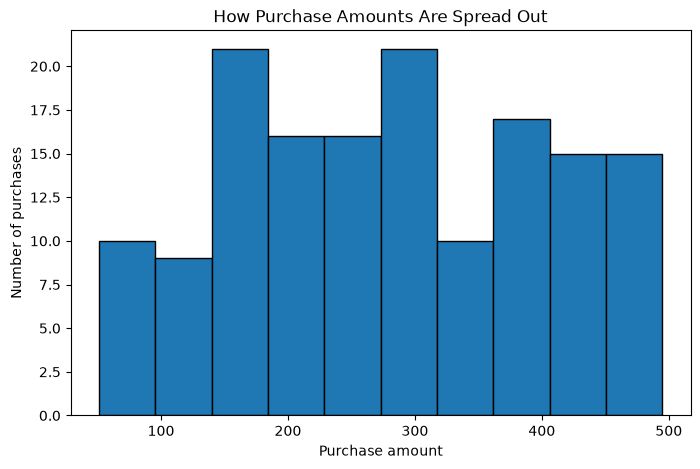

In [12]:
# Draw a bar chart (a histogram) that shows how many purchases fall into each price range

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(merged["purchase_amount"], bins=10, edgecolor="black")
plt.title("How Purchase Amounts Are Spread Out")
plt.xlabel("Purchase amount")
plt.ylabel("Number of purchases")
plt.show()

## 13. Plot 2: Looking for Unusual Values

Customer ratings and engagement scores have no unusual values. A few customers have very low purchase interest scores (about 1.0 to 1.4). These are valid scores on the 1 to 5 scale and not errors, so we keep them.

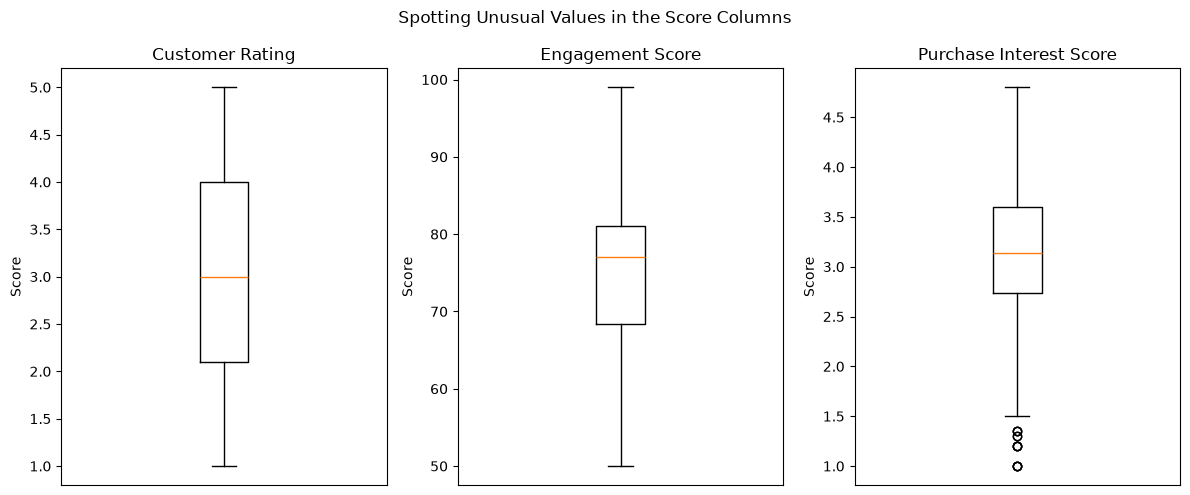

In [13]:
# Draws another box plot for each of the three score columns to look for unusual values

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

columns = ["customer_rating", "engagement_score", "purchase_interest_score"]
titles = ["Customer Rating", "Engagement Score", "Purchase Interest Score"]

for ax, col, title in zip(axes, columns, titles):
    ax.boxplot(merged[col])
    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_xticks([])

plt.suptitle("Spotting Unusual Values in the Score Columns")
plt.tight_layout()
plt.show()

## 14. Plot 3: Relationships Between Number Columns

All the relationships between the number columns are weak (every value is below 0.2). The strongest are engagement score with purchase interest (0.19) and customer rating with purchase interest (0.16). No column duplicates another, but no single column predicts another either, so predicting the product is expected to be hard.

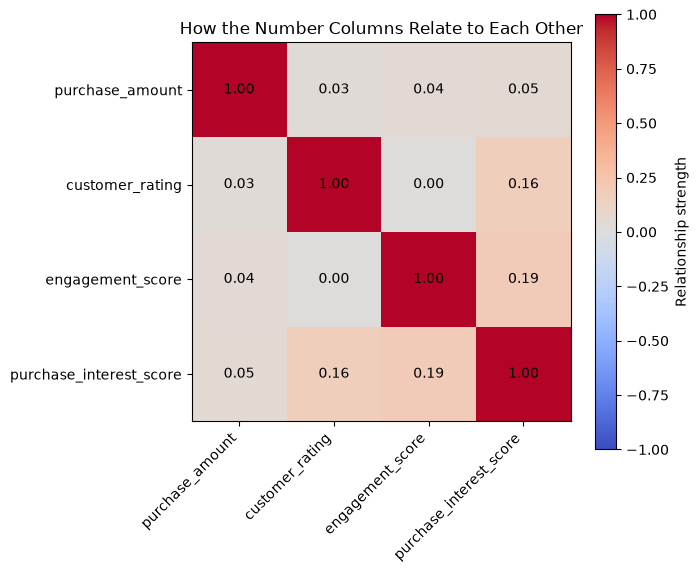

In [14]:
# Draw a 3rd plot (colored grid) to determine which columns move together

cols = ["purchase_amount", "customer_rating", "engagement_score", "purchase_interest_score"]
corr = merged[cols].corr()

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Relationship strength")
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("How the Number Columns Relate to Each Other")
plt.tight_layout()
plt.show()

## 15. Create Date Features

We turn the purchase date into the month, the day of the week and a weekend flag, because a model cannot use a raw date. The data covers January to May 2024 with one purchase per day, so these features may not add much.

In [15]:
# Create new columns from the purchase date

merged["purchase_month"] = merged["purchase_date"].dt.month
merged["purchase_day_of_week"] = merged["purchase_date"].dt.dayofweek   # 0 = Monday, 6 = Sunday
merged["is_weekend"] = (merged["purchase_day_of_week"] >= 5).astype(int)

print(merged[["purchase_date", "purchase_month", "purchase_day_of_week", "is_weekend"]].head(10))
print()
print(merged["purchase_month"].value_counts().sort_index())

  purchase_date  purchase_month  purchase_day_of_week  is_weekend
0    2024-01-01               1                     0           0
1    2024-01-02               1                     1           0
2    2024-01-03               1                     2           0
3    2024-01-04               1                     3           0
4    2024-01-05               1                     4           0
5    2024-01-06               1                     5           1
6    2024-01-07               1                     6           1
7    2024-01-08               1                     0           0
8    2024-01-09               1                     1           0
9    2024-01-10               1                     2           0

purchase_month
1    31
2    29
3    31
4    30
5    29
Name: count, dtype: int64


## 16. Turn Text Columns into Numbers

We convert the platform and sentiment columns into separate 0/1 columns (one-hot encoding), including an "Unknown" column for customers without a social profile. This gives the model numbers instead of text.

In [16]:
# Turn the text columns into numbers

dummies = pd.get_dummies(merged[["social_media_platform", "review_sentiment"]], dtype=int)

# remove old copies first, so running this cell twice doesn't duplicate columns
merged = merged.drop(columns=[c for c in dummies.columns if c in merged.columns])
merged = pd.concat([merged, dummies], axis=1)

print("New columns added:")
print(list(dummies.columns))
print()
print("Merged shape now:", merged.shape)
print(dummies.head())

New columns added:
['social_media_platform_Facebook', 'social_media_platform_Instagram', 'social_media_platform_LinkedIn', 'social_media_platform_TikTok', 'social_media_platform_Twitter', 'social_media_platform_Unknown', 'review_sentiment_Negative', 'review_sentiment_Neutral', 'review_sentiment_Positive', 'review_sentiment_Unknown']

Merged shape now: (150, 25)
   social_media_platform_Facebook  social_media_platform_Instagram  \
0                               0                                0   
1                               0                                1   
2                               1                                0   
3                               0                                0   
4                               0                                1   

   social_media_platform_LinkedIn  social_media_platform_TikTok  \
0                               0                             0   
1                               0                             0   
2             

## 17. Save the Merged Dataset

We save the merged table with all engineered features to data/merged_dataset.csv. It has 150 rows and 25 columns, and we reload it to confirm that it saved correctly.

In [17]:
# Save the merged dataset 

merged.to_csv("data/merged_dataset.csv", index=False)

check = pd.read_csv("data/merged_dataset.csv")
print("Saved and reloaded shape:", check.shape)
print(list(check.columns))

Saved and reloaded shape: (150, 25)
['customer_id_legacy', 'transaction_id', 'purchase_amount', 'purchase_date', 'product_category', 'customer_rating', 'customer_id', 'engagement_score', 'purchase_interest_score', 'social_media_platform', 'review_sentiment', 'has_social_profile', 'purchase_month', 'purchase_day_of_week', 'is_weekend', 'social_media_platform_Facebook', 'social_media_platform_Instagram', 'social_media_platform_LinkedIn', 'social_media_platform_TikTok', 'social_media_platform_Twitter', 'social_media_platform_Unknown', 'review_sentiment_Negative', 'review_sentiment_Neutral', 'review_sentiment_Positive', 'review_sentiment_Unknown']


## 18. Prepare the Data for the Model

We split the data into the inputs (18 columns) and the answer, the product category. The ID columns, the raw date and the original text columns are left out because they give the model no useful clue. We use 80% of the rows (120) for training and keep 20% (30) as a test set the model has never seen. The split keeps the product mix the same in both parts.

In [18]:
from sklearn.model_selection import train_test_split

# the answer we want the model to predict
y = merged["product_category"]

# the columns the model is allowed to look at
drop_cols = ["customer_id_legacy", "transaction_id", "customer_id", "purchase_date",
             "product_category", "social_media_platform", "review_sentiment"]
X = merged.drop(columns=drop_cols)

# 80% to learn from, 20% to test on (stratify keeps the product mix equal in both)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Input columns used:", X.shape[1])
print(list(X.columns))
print()
print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print()
print("Products in the test set:")
print(y_test.value_counts())

Input columns used: 18
['purchase_amount', 'customer_rating', 'engagement_score', 'purchase_interest_score', 'has_social_profile', 'purchase_month', 'purchase_day_of_week', 'is_weekend', 'social_media_platform_Facebook', 'social_media_platform_Instagram', 'social_media_platform_LinkedIn', 'social_media_platform_TikTok', 'social_media_platform_Twitter', 'social_media_platform_Unknown', 'review_sentiment_Negative', 'review_sentiment_Neutral', 'review_sentiment_Positive', 'review_sentiment_Unknown']

Training rows: 120
Test rows: 30

Products in the test set:
product_category
Sports         7
Electronics    7
Clothing       6
Groceries      5
Books          5
Name: count, dtype: int64


## 19. Train and Evaluate the Product Recommendation Model

We first train a Random Forest with no limits. It scores 1.0 on the training rows but only 0.167 on the test rows, with a loss of 1.908. This is overfitting: the model memorized the training rows instead of learning patterns that carry over to new data.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

test_pred = model.predict(X_test)
test_proba = model.predict_proba(X_test)

print("Accuracy on training rows:", round(accuracy_score(y_train, model.predict(X_train)), 3))
print("Accuracy on test rows:   ", round(accuracy_score(y_test, test_pred), 3))
print("F1-score on test rows:   ", round(f1_score(y_test, test_pred, average="weighted"), 3))
print("Loss on test rows:       ", round(log_loss(y_test, test_proba, labels=model.classes_), 3))

Accuracy on training rows: 1.0
Accuracy on test rows:    0.167
F1-score on test rows:    0.152
Loss on test rows:        1.908


## 20. Compare Simpler Models with Cross-Validation

With only 30 test rows, a single split is unreliable. We use 5-fold cross-validation on all 150 rows to compare three models. The average accuracies are 0.247 for the original Random Forest, 0.247 for a shallow Random Forest and 0.227 for Logistic Regression. All are close to random guessing (0.20), and the differences between them are within normal variation.

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Random Forest (original)": RandomForestClassifier(n_estimators=100, random_state=42),
    "Random Forest (shallow)": RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    print(f"{name}: average accuracy {scores.mean():.3f}  (the 5 scores: {scores.round(2)})")

print()
print("Random guessing would score about 0.20")

Random Forest (original): average accuracy 0.247  (the 5 scores: [0.17 0.27 0.23 0.23 0.33])


Random Forest (shallow): average accuracy 0.247  (the 5 scores: [0.2  0.23 0.2  0.3  0.3 ])
Logistic Regression: average accuracy 0.227  (the 5 scores: [0.1  0.27 0.27 0.27 0.23])

Random guessing would score about 0.20


## 21. Train and Evaluate the Final Product Model

We choose the shallow Random Forest because it scores the same as the others but memorizes less. Its training accuracy drops to 0.633. On the test rows it gets an accuracy of 0.2, an F1-score of 0.174 and a loss of 1.675. This is close to random guessing (accuracy 0.20, loss about 1.61). We explain it by the small dataset (150 rows) and the weak relationships between the features and the product category.

In [21]:
final_model = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=42)
final_model.fit(X_train, y_train)

test_pred = final_model.predict(X_test)
test_proba = final_model.predict_proba(X_test)

print("Accuracy on training rows:", round(accuracy_score(y_train, final_model.predict(X_train)), 3))
print("Accuracy on test rows:   ", round(accuracy_score(y_test, test_pred), 3))
print("F1-score on test rows:   ", round(f1_score(y_test, test_pred, average="weighted"), 3))
print("Loss on test rows:       ", round(log_loss(y_test, test_proba, labels=final_model.classes_), 3))

Accuracy on training rows: 0.633
Accuracy on test rows:    0.2
F1-score on test rows:    0.174
Loss on test rows:        1.675


## 22. Save the Product Model

We save the final model and its list of input columns to the models folder, so the command-line app can load them without retraining. We load the model back and make one prediction to check the file works.

In [22]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/product_model.pkl")
joblib.dump(list(X.columns), "models/product_model_columns.pkl")

# check: load it back and make one test prediction
loaded = joblib.load("models/product_model.pkl")
print("Model loaded back OK. Classes it can predict:", list(loaded.classes_))
print("Prediction for the first test row:", loaded.predict(X_test.iloc[[0]])[0])

Model loaded back OK. Classes it can predict: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']
Prediction for the first test row: Clothing


# Part 2: Image Data and Facial Recognition

This part covers the face side of the system. Each team member took three photos: one neutral, one smiling and one surprised. We load and display the photos, create changed copies of each one (augmentation), turn every image into a row of numbers (features) saved in `data/image_features.csv`, and train a model that recognises who is in the photo.

The functions used here are in `scripts/image_pipeline.py` (loading, augmentation, features) and `scripts/face_model.py` (the face model). The command-line app imports the same code, so the notebook and the app process images the same way. The extra libraries needed are `pillow` and `scikit-image` (`opencv-python` is optional and is only used to find the face).

## I1. Load Data

Photos are in the `images/` folder and named `<member>_<expression>`, for example `selena_neutral.jpeg`, so the member and the expression can be read from the file name. Every photo goes through the same steps: its rotation is fixed (phones store the direction in the file instead of turning the picture), the face is found and cropped, and the crop is resized to 128 x 128 pixels. This makes photos from different phones comparable. Files starting with `unauthorized` are people outside the team. They are kept apart and only used at the end to test that strangers are rejected.

In [23]:
import sys
sys.path.insert(0, "scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from image_pipeline import (FACE_SIZE, EXPRESSIONS, list_images, load_image, parse_name,
                            augment, build_feature_table, FEATURES_PATH)

photos = list_images()
faces = {}          # sample_id -> cropped face
summary = []
for path in photos:
    member, expression = parse_name(path)
    faces[path.stem.lower()] = load_image(path)
    summary.append({"file": path.name, "member": member, "expression": expression})

photo_info = pd.DataFrame(summary)
print(f"{len(photos)} photos from {photo_info['member'].nunique()} members, each cropped to {FACE_SIZE} x {FACE_SIZE}")
display(pd.crosstab(photo_info["member"], photo_info["expression"]))

9 photos from 3 members, each cropped to 128 x 128


expression,neutral,smiling,surprised
member,,,
celine,1,1,1
joshua,1,1,1
selena,1,1,1


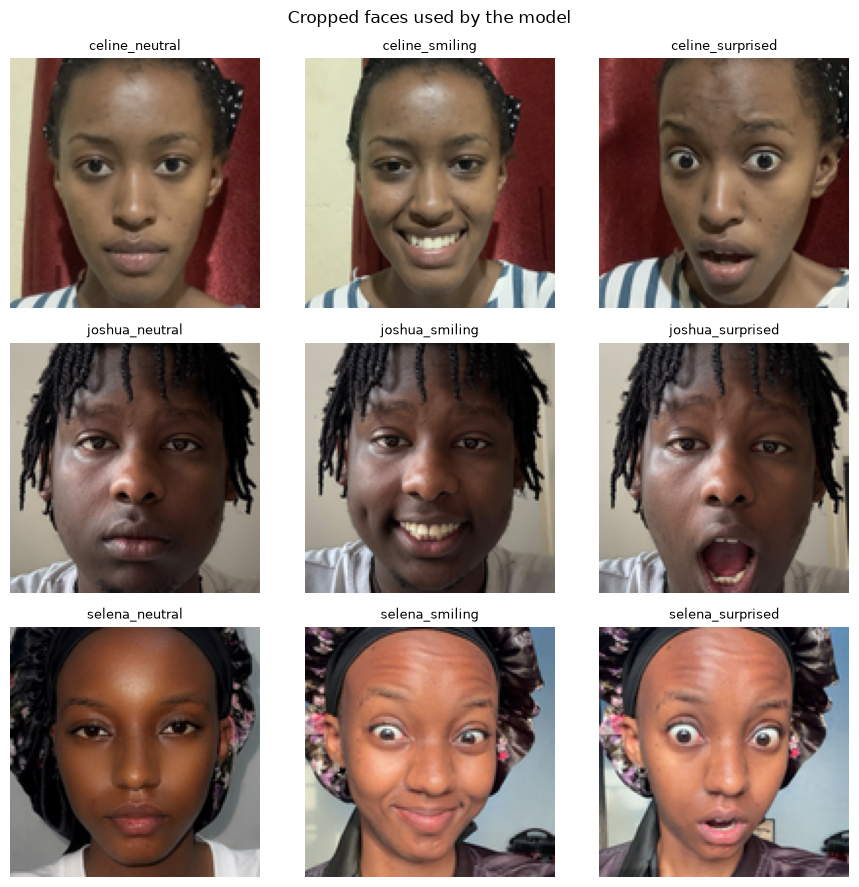

In [24]:
# show every member's photos: one row per member, one column per expression
members = sorted(photo_info["member"].unique())
fig, axes = plt.subplots(len(members), len(EXPRESSIONS), figsize=(3 * len(EXPRESSIONS), 3 * len(members)), squeeze=False)
for r, member in enumerate(members):
    for c, expression in enumerate(EXPRESSIONS):
        ax = axes[r, c]
        ax.axis("off")
        sample_id = f"{member}_{expression}"
        if sample_id in faces:
            ax.imshow(faces[sample_id])
            ax.set_title(sample_id, fontsize=9)
        else:
            ax.set_title(f"{sample_id}: MISSING", fontsize=9, color="red")
plt.suptitle("Cropped faces used by the model")
plt.tight_layout()
plt.show()

## I2. Augmentation

With only three photos per person, a model would have very little to learn from. We create six changed copies of every photo. Each one imitates something that happens in real use:

| Augmentation | What it does | Real-life situation |
|---|---|---|
| `rotate_left` / `rotate_right` | turns the face 15 degrees each way | head slightly tilted |
| `flip` | mirrors the face left to right | a selfie camera that mirrors the image |
| `grayscale` | removes the colour | a black-and-white or poor-quality camera |
| `brighter` / `darker` | 40% brighter / 40% darker | a bright window or a dim room |

Each photo gives 7 versions (the original plus 6 copies), so every member has 21 rows instead of 3. Below are all seven versions of one photo.

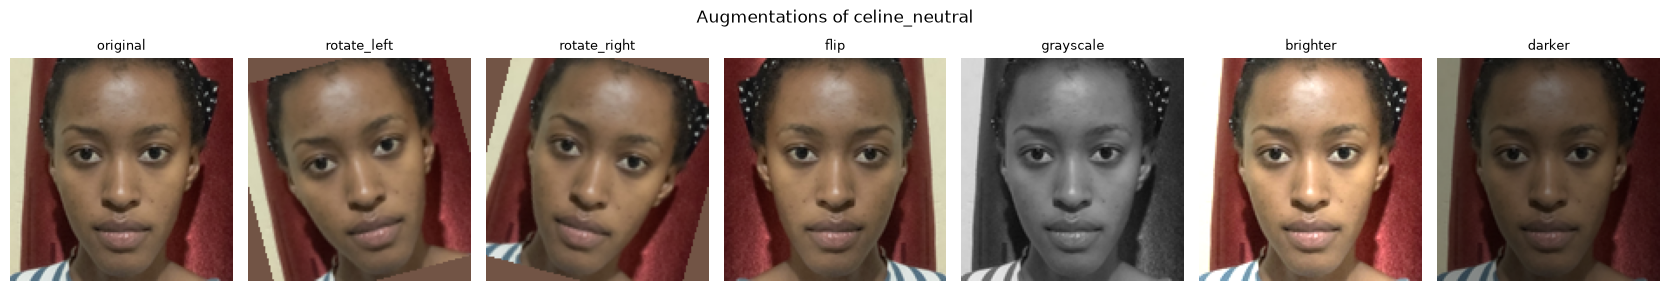

In [25]:
example_id = next(iter(faces))
versions = augment(faces[example_id])

fig, axes = plt.subplots(1, len(versions), figsize=(2.4 * len(versions), 3))
for ax, (name, img) in zip(axes, versions.items()):
    ax.imshow(img)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.suptitle(f"Augmentations of {example_id}")
plt.tight_layout()
plt.show()

## I3. Extract features and save image_features.csv

A model cannot read a picture, so every face is turned into a row of 948 numbers:

- **HOG (900 values):** Histogram of Oriented Gradients. The face is shrunk to 96 x 96 and cut into 16 x 16 pixel cells. For each cell we record which directions the edges point in. This captures the layout of the eyes, nose, mouth and jaw line, which is the main feature for telling faces apart.
- **Colour histogram (48 values):** how many pixels fall into each of 16 brightness levels for red, green and blue. This captures skin tone and lighting.

The first three columns (`member`, `sample_id`, `augmentation`) match the layout of `audio_features.csv`. The other 948 columns are the features.

In [26]:
image_features = build_feature_table()
FEATURES_PATH.parent.mkdir(exist_ok=True)
image_features.to_csv(FEATURES_PATH, index=False)

# check: reload the file and confirm it is complete
check = pd.read_csv(FEATURES_PATH)
print("Saved to data/image_features.csv:", check.shape)
print("Missing values:", int(check.isna().sum().sum()))
print()
print(pd.crosstab(check["member"], check["augmentation"]))
check.iloc[:, :8].head()

Saved to data/image_features.csv: (63, 951)
Missing values: 0

augmentation  brighter  darker  flip  grayscale  original  rotate_left  \
member                                                                   
celine               3       3     3          3         3            3   
joshua               3       3     3          3         3            3   
selena               3       3     3          3         3            3   

augmentation  rotate_right  
member                      
celine                   3  
joshua                   3  
selena                   3  


,member,sample_id,augmentation,hog_0,hog_1,hog_2,hog_3,hog_4
0,celine,celine_neutral,original,0.459710,0.024084,0.018804,0.008173,0.009526
1,celine,celine_neutral,rotate_left,0.121737,0.184640,0.190516,0.228589,0.177906
2,celine,celine_neutral,rotate_right,0.354652,0.354652,0.011747,0.011531,0.003110
3,celine,celine_neutral,flip,0.248205,0.236562,0.100410,0.137035,0.217202
4,celine,celine_neutral,grayscale,0.458688,0.021143,0.023175,0.008146,0.009178


## I4. Compare the Faces

Before training, we check whether the features differ between members. If every member's numbers sit on top of each other, no model could tell them apart. We squash the 948 features down to 2 with PCA, a method that keeps as much of the variation as possible, and plot every row. Each dot is one image, and each colour is one member.

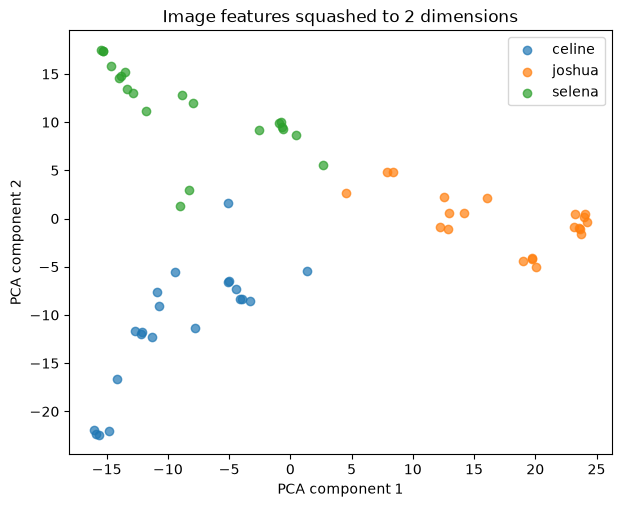

In [27]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

feature_cols = [c for c in image_features.columns if c not in ["member", "sample_id", "augmentation"]]
points = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(image_features[feature_cols]))

plt.figure(figsize=(7, 5.5))
for m in sorted(image_features["member"].unique()):
    mask = (image_features["member"] == m).values
    plt.scatter(points[mask, 0], points[mask, 1], label=m, alpha=0.7)
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("Image features squashed to 2 dimensions")
plt.legend()
plt.show()

## I5. Train and Evaluate the Facial Recognition Model

A random split would put rotated or brightened copies of the same photo in both the training and the test set, and the model would score well just by remembering the photo. Instead we use a **leave-one-expression-out** test: train on two expressions (for example neutral and smiling) and test on the third (surprised), then repeat for each expression. The test photo and all its augmented copies are never seen in training, so a good score means the model recognises the person, not the picture.

We compare Logistic Regression and a Random Forest (both after scaling the features) and report accuracy, macro F1-score and log loss for each. The final model is trained on all rows and saved to `models/face_model.pkl`.

,Accuracy,F1-score,Loss
Logistic Regression,0.968,0.969,0.122
Random Forest,0.968,0.968,0.419


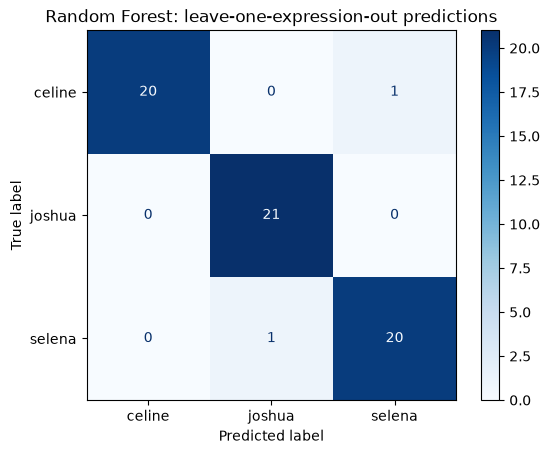

In [28]:
from face_model import load_features, evaluate, train_and_save
from sklearn.metrics import ConfusionMatrixDisplay

face_data, face_cols = load_features()
if face_data["member"].nunique() < 2 or face_data["expression"].nunique() < 2:
    print("Need at least 2 members and 2 expressions in images/. Add the missing photos and rerun this section.")
else:
    face_results = train_and_save()
    scores = pd.DataFrame({name: {"Accuracy": r["accuracy"], "F1-score": r["f1"], "Loss": r["loss"]}
                           for name, r in face_results.items()}).T.round(3)
    display(scores)

    best_face_model = "Random Forest"   # the model the app uses (see the explanation below)
    ConfusionMatrixDisplay.from_predictions(face_results[best_face_model]["y_true"],
                                            face_results[best_face_model]["y_pred"], cmap="Blues")
    plt.title(f"{best_face_model}: leave-one-expression-out predictions")
    plt.show()

**Results:** both models reach 0.968 accuracy. Logistic Regression has a very slightly higher F1-score (0.969 against 0.968) and a lower loss (0.12 against 0.42), but we use the **Random Forest** in the app. The reason is how each model behaves on a face it has never seen. Logistic Regression is overconfident: it accepted the stranger photo as Celine with 85% confidence, which passes the 70% cutoff. The Random Forest spreads its votes across members for an unfamiliar face (47% for the stranger), so the confidence check can reject strangers. Only 2 of 63 test rows are wrong, and both are augmented copies (a rotated Selena photo and a flipped Celine photo), not original photos.

## I6. Face Verification and Unauthorized Attempts

In the app, the face check is the first gate. A photo is approved only if both checks pass:

1. **Confidence:** the model is at least 70% sure who it is.
2. **Distance:** the face is not much further from that member's average face than the member's own held-out photos were.

We test every team photo (should be approved) and every `unauthorized_*` photo of a person outside the team (should be denied).

In [29]:
from face_model import verify_face, MODEL_PATH as FACE_MODEL_PATH

if not FACE_MODEL_PATH.exists():
    print("No face model saved yet. Run section I5 first.")
else:
    face_tests = []
    for path in list_images():
        owner, _ = parse_name(path)
        r = verify_face(path)
        face_tests.append({"image": path.name, "who_is_it": owner, "expected": "approve", **r})
    for path in [p for p in list_images(include_unauthorized=True) if p not in photos]:
        r = verify_face(path)
        face_tests.append({"image": path.name, "who_is_it": "stranger", "expected": "deny", **r})

    face_table = pd.DataFrame(face_tests)[["image", "who_is_it", "expected", "approved", "predicted_member", "confidence", "distance", "reason"]]
    face_table["correct"] = ((face_table["expected"] == "approve") == face_table["approved"]) & \
                            ((face_table["expected"] == "deny") | (face_table["predicted_member"] == face_table["who_is_it"]))
    face_table[["confidence", "distance"]] = face_table[["confidence", "distance"]].round(2)
    print(f"{face_table['correct'].sum()} of {len(face_table)} decisions correct")
    display(face_table)

10 of 10 decisions correct


,image,who_is_it,expected,approved,predicted_member,confidence,distance,reason,correct
0,celine_neutral.jpg,celine,approve,True,celine,0.99,0.61,face recognised,True
1,celine_smiling.jpg,celine,approve,True,celine,1.00,0.80,face recognised,True
2,celine_surprised.jpg,celine,approve,True,celine,0.97,0.81,face recognised,True
3,joshua_neutral.jpg,joshua,approve,True,joshua,1.00,0.55,face recognised,True
4,joshua_smiling.jpg,joshua,approve,True,joshua,0.98,0.64,face recognised,True
5,joshua_surprised.jpg,joshua,approve,True,joshua,1.00,0.58,face recognised,True
6,selena_neutral.jpeg,selena,approve,True,selena,0.97,0.75,face recognised,True
7,selena_smiling.jpeg,selena,approve,True,selena,1.00,0.66,face recognised,True
8,selena_surprised.jpeg,selena,approve,True,selena,0.98,0.64,face recognised,True
9,unauthorized_person.jpg,stranger,deny,False,None,0.47,1.25,low confidence (0.47 < 0.7),True


**What the face tests show:** all 10 decisions are correct. Every member's photos are approved with 97 to 100% confidence, and the stranger photo is denied because the model is only 47% sure who it is (cutoff 70%). The stranger's distance (1.25) was still within the limit, so the confidence check is what stops them. We tested only one stranger photo, so 70% is a demonstration setting, not a proven security level.

# Part 3: Audio Data and Voiceprint Verification

This part covers the voice side of the system. Each team member recorded two phrases, "Yes, approve" and "Confirm transaction". We load and plot the clips, create changed copies of each one (augmentation), turn every clip into a row of numbers (features), and train a model that recognises who is speaking.

The functions used here are in `scripts/audio_pipeline.py` (loading, augmentation, features) and `scripts/voice_model.py` (the voice model). The command-line app imports the same code, so the notebook and the app process audio the same way.

## A1. Load the Audio Clips

Clips are named `<member>_<phrase>`, for example `selena_yes_approve.mp4`, so the member and phrase can be read from the file name. Each clip is converted to mono at 16 kHz, which is enough for speech. The silence at the start and end is cut, and the volume is scaled so the loudest point is 1. This makes clips recorded on different phones comparable. Files starting with `unauthorized` are kept apart and only used at the end to test that strangers are rejected.

In [30]:
import sys
sys.path.insert(0, "scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display

from audio_pipeline import (SAMPLE_RATE, list_clips, load_audio, parse_name,
                            augment, build_feature_table, FEATURES_PATH)

clips = list_clips()
audio = {}          # sample_id -> waveform
summary = []
for path in clips:
    member, phrase = parse_name(path)
    y = load_audio(path)
    audio[path.stem.lower()] = y
    summary.append({"file": path.name, "member": member, "phrase": phrase,
                    "duration_s": round(len(y) / SAMPLE_RATE, 2)})

clip_info = pd.DataFrame(summary)
print(f"{len(clips)} clips from {clip_info['member'].nunique()} members, sample rate {SAMPLE_RATE} Hz")
clip_info

6 clips from 3 members, sample rate 16000 Hz


,file,member,phrase,duration_s
0,Celine_Confirm_transaction.wav,celine,confirm_transaction,1.98
1,celine_yes_approve.wav,celine,yes_approve,1.76
2,joshua_confirm_transaction.mp4,joshua,confirm_transaction,3.13
3,joshua_yes_approve.mp4,joshua,yes_approve,2.94
4,selena_confirm_transaction.mp4,selena,confirm_transaction,1.34
5,selena_yes_approve.mp4,selena,yes_approve,1.22


In [31]:
# listen to each clip
for sample_id, y in audio.items():
    print(sample_id)
    display(Audio(y, rate=SAMPLE_RATE))

celine_confirm_transaction


celine_yes_approve


joshua_confirm_transaction


joshua_yes_approve


selena_confirm_transaction


selena_yes_approve


## A2. Waveforms

A waveform shows how loud the sound is over time. Each burst is a word or syllable, and the quiet gaps between them are pauses.

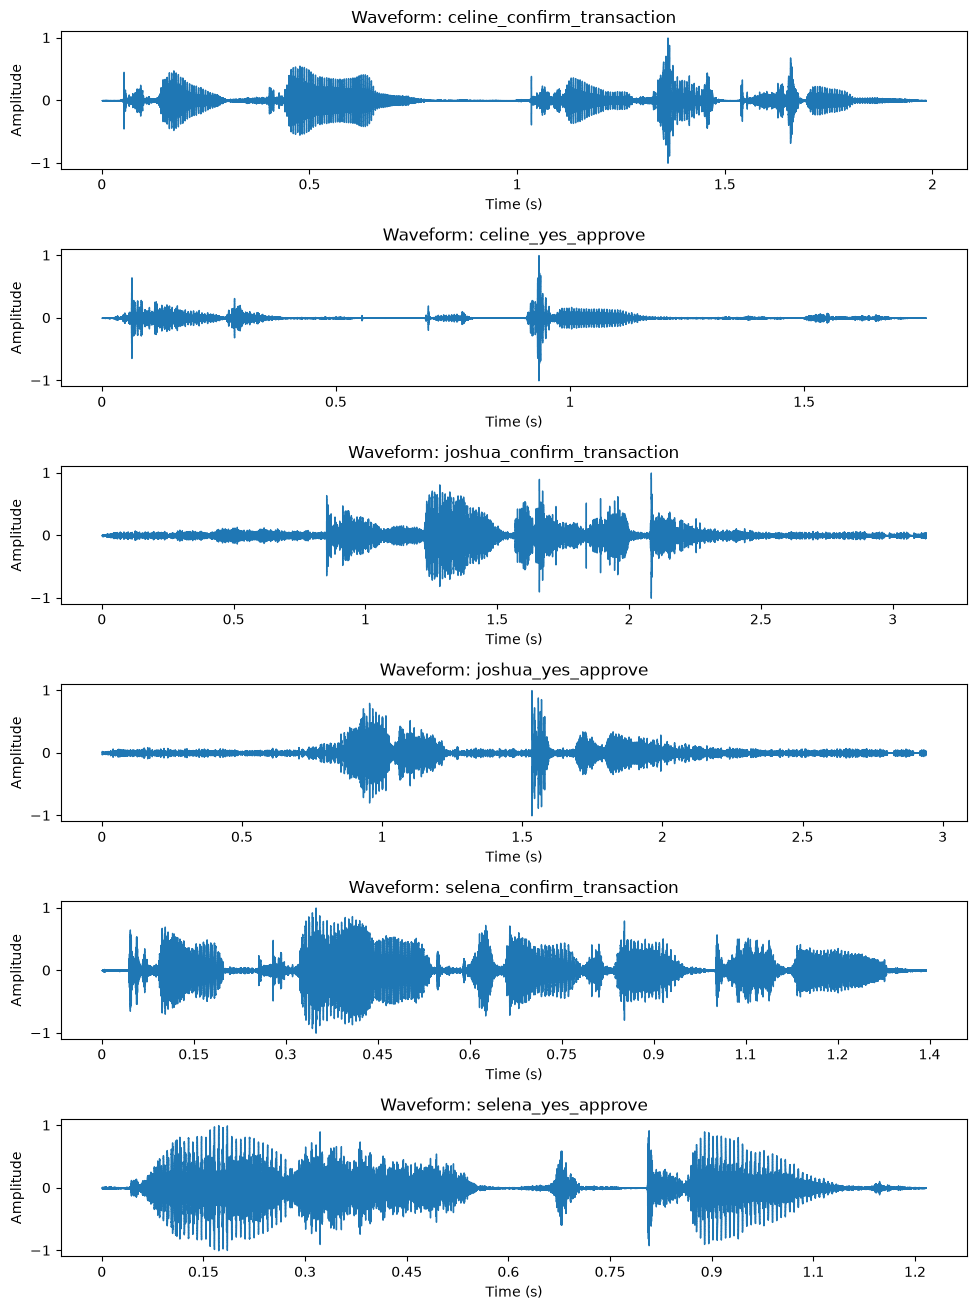

In [32]:
fig, axes = plt.subplots(len(audio), 1, figsize=(10, 2.2 * len(audio)), squeeze=False)
for ax, (sample_id, y) in zip(axes[:, 0], audio.items()):
    librosa.display.waveshow(y, sr=SAMPLE_RATE, ax=ax)
    ax.set_title(f"Waveform: {sample_id}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

The three members' recordings look quite different:

- **Selena** (about 1.2 to 1.4 s): very clean. The line is flat between words, so there is almost no background noise. "Confirm transaction" breaks into many short bursts, one per syllable (con-firm-trans-ac-tion). "Yes, approve" has a long first burst for "yes", a short gap, a sharp spike near 0.8 s from the "p" in "approve", and a final burst for "-prove".
- **Celine** (about 1.8 to 2.0 s): also clean, with flat gaps between words. She speaks more slowly, with a clear pause between "yes" and "approve" and a sharp "p" spike just after 0.9 s.
- **Joshua** (about 3 s): there is a steady low hum under the whole clip, so the line is never flat. Because this background noise is above the level the trimming step treats as silence, the quiet start and end were not cut, and the clips stay about twice as long. The speech itself sits between about 0.8 and 2.2 s.

Every clip peaks at 1 because of the volume scaling, so loudness differences between phones do not affect the model. The background noise in Joshua's clips does, which shows up again in the results of section A7.

## A3. Spectrograms

A spectrogram shows which frequencies are present at each moment. Brighter colours mean more energy. We use a mel scale, which spaces the frequencies the way human hearing does. The horizontal bands in the voiced parts are the speaker's harmonics and formants. Their spacing and position depend on the shape of the person's throat and mouth, which is what makes a voice recognisable.

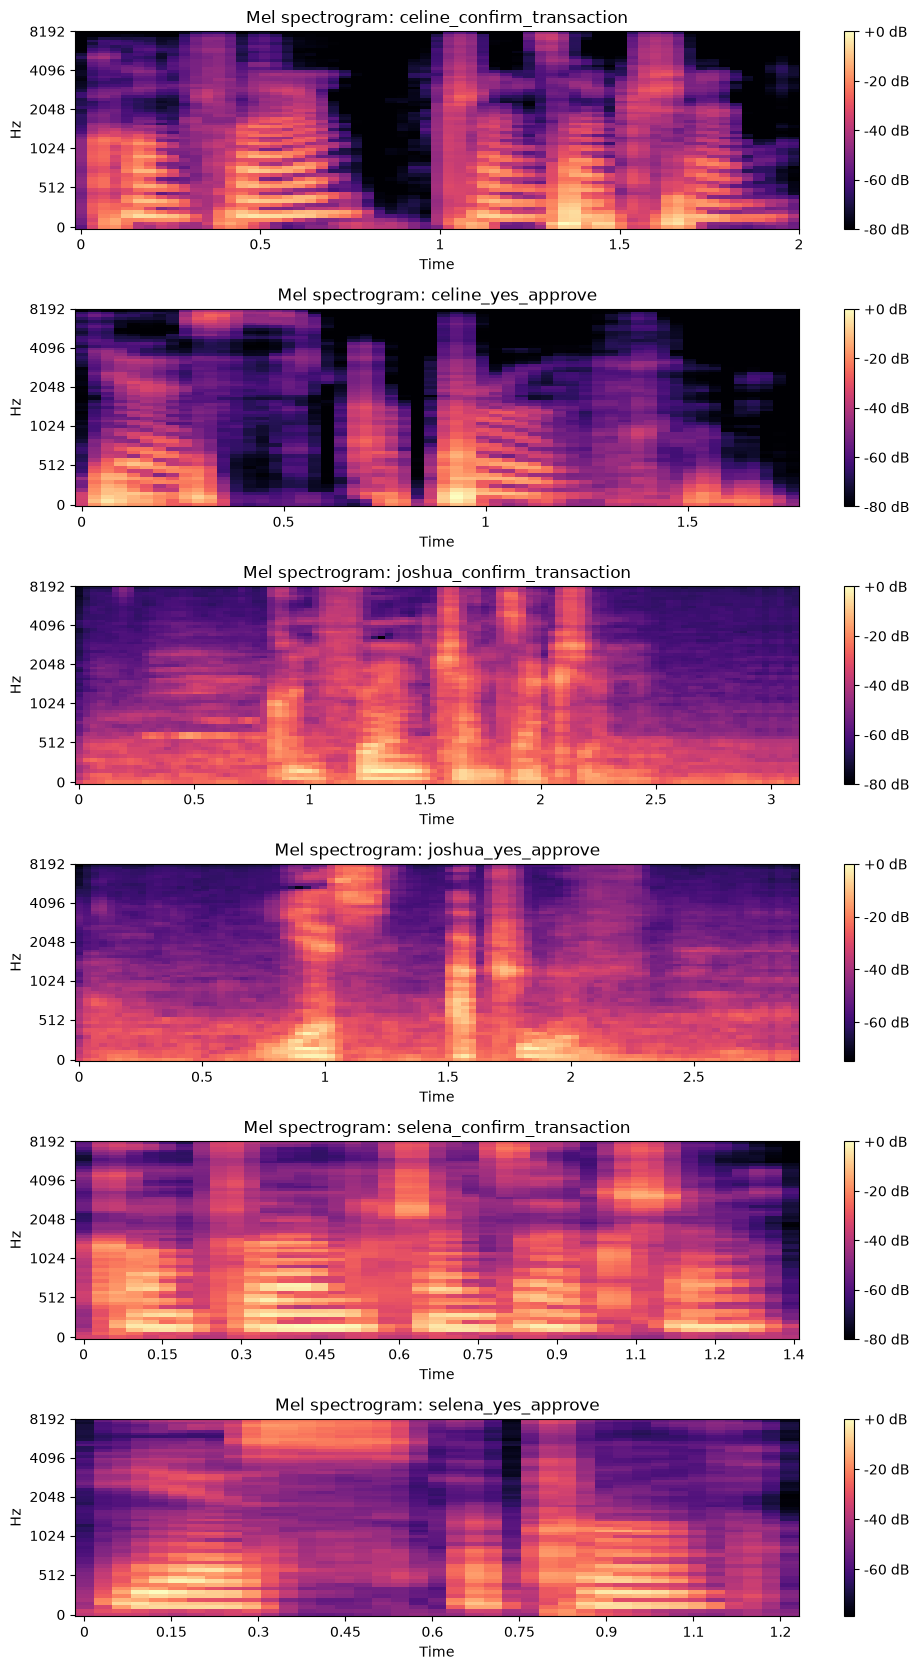

In [33]:
fig, axes = plt.subplots(len(audio), 1, figsize=(10, 2.8 * len(audio)), squeeze=False)
for ax, (sample_id, y) in zip(axes[:, 0], audio.items()):
    mel = librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_mels=64)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = librosa.display.specshow(mel_db, sr=SAMPLE_RATE, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(f"Mel spectrogram: {sample_id}")
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout()
plt.show()

The vowels show as stacks of bright horizontal lines below about 1 kHz. These are the harmonics of the voice, and their spacing is set by the speaker's pitch. In Selena's "Yes, approve" clip, the "s" at the end of "yes" (about 0.3 to 0.55 s) looks completely different: its energy is spread across 4 to 8 kHz with no lines, because an "s" is a hiss rather than a tone. "Confirm transaction" has several of these high-frequency patches from its "s", "sh" and "t" sounds. The MFCC features in section A5 summarise exactly this pattern: where the bright bands sit and how the energy is spread.

Joshua's spectrograms have no dark (silent) areas at all: the background hum fills every frequency for the whole clip, and his harmonics are fainter on top of it. Celine's and Selena's clips have clear black gaps between words.

## A4. Augmentation

With only two clips per person, a model would have very little to learn from. We create five changed copies of every clip. Each one imitates something that happens in real use:

| Augmentation | What it does | Real-life situation |
|---|---|---|
| `pitch_up` / `pitch_down` | voice 1.5 semitones higher / lower | a cold, being tired or excited |
| `time_fast` / `time_slow` | 20% faster / slower, same pitch | speaking in a hurry or carefully |
| `noise` | background hiss at 20 dB signal-to-noise | a noisy room |

Each clip gives 6 versions (the original plus 5 copies), so every member has 12 rows instead of 2. Below are all six versions of one clip.

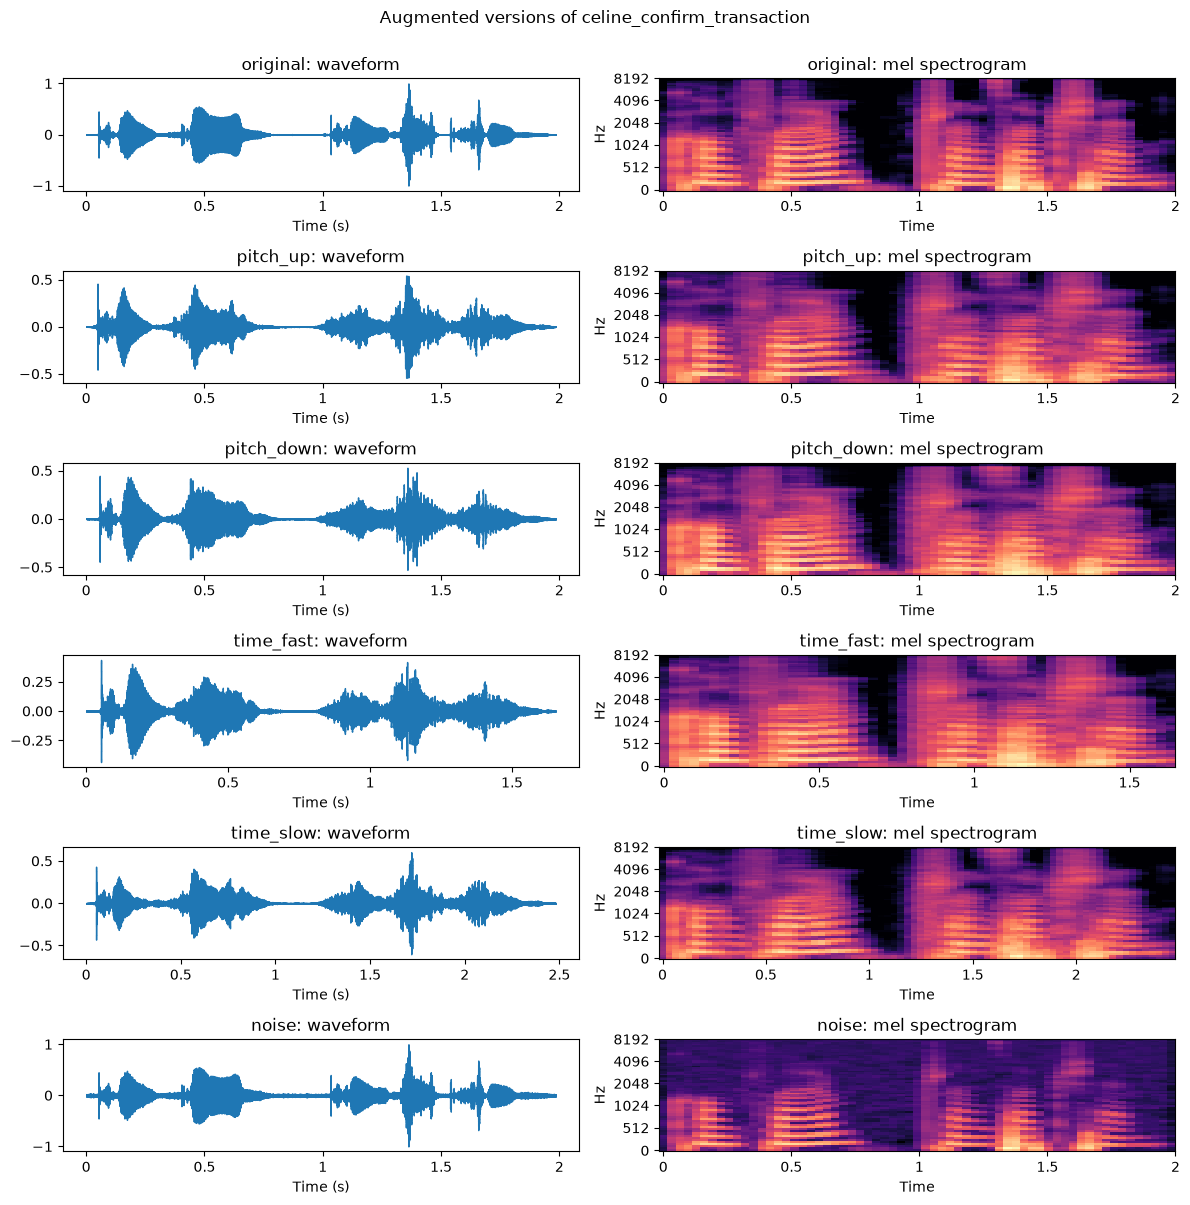

original


pitch_up


pitch_down


time_fast


time_slow


noise


In [34]:
example_id = next(iter(audio))
versions = augment(audio[example_id])

fig, axes = plt.subplots(len(versions), 2, figsize=(12, 2.0 * len(versions)))
for row, (name, y_aug) in enumerate(versions.items()):
    librosa.display.waveshow(y_aug, sr=SAMPLE_RATE, ax=axes[row, 0])
    axes[row, 0].set_title(f"{name}: waveform")
    axes[row, 0].set_xlabel("Time (s)")
    mel_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y_aug, sr=SAMPLE_RATE, n_mels=64), ref=np.max)
    librosa.display.specshow(mel_db, sr=SAMPLE_RATE, x_axis="time", y_axis="mel", ax=axes[row, 1])
    axes[row, 1].set_title(f"{name}: mel spectrogram")
fig.suptitle(f"Augmented versions of {example_id}", y=1.0)
plt.tight_layout()
plt.show()

for name, y_aug in versions.items():
    print(name)
    display(Audio(y_aug, rate=SAMPLE_RATE))

- **Pitch up / down:** the harmonic lines in the spectrogram move further apart or closer together, while the clip stays the same length.
- **Time fast / slow:** the clip becomes shorter (about 1.1 s) or longer (about 1.7 s), but the bands stay at the same height, so the pitch is unchanged.
- **Pitch and time changes:** these also smooth the waveform slightly. This is a side effect of the method librosa uses (a phase vocoder).
- **Noise:** at 20 dB the hiss is quiet compared with the voice, so the waveform looks almost the same. You can hear it mainly in the pauses.

In every version the words and their order are still clear, so each copy is still a valid example of the same person saying the same phrase.

## A5. Extract Features and Save audio_features.csv

A model needs the same number of inputs for every clip, but clips have different lengths. We measure each feature over short frames (about 32 ms each) and then keep its mean and standard deviation across the whole clip:

- **MFCCs (13 coefficients):** a compact description of the shape of the voice's spectrum. This is the main voiceprint feature.
- **Spectral roll-off:** the frequency below which 85% of the energy sits.
- **RMS energy:** how loud the voice is, frame by frame.
- **Spectral centroid:** the "brightness" of the voice.
- **Zero-crossing rate:** how noisy or hissy the sound is.

This gives 13 × 2 + 4 × 2 = 34 features per row. The first three columns (`member`, `sample_id`, `augmentation`) match the layout of `image_features.csv`.

In [35]:
audio_features = build_feature_table()
audio_features.to_csv(FEATURES_PATH, index=False)

# check: reload the file and confirm it is complete
check = pd.read_csv(FEATURES_PATH)
print("Saved to data/audio_features.csv:", check.shape)
print("Missing values:", int(check.isna().sum().sum()))
print()
print(pd.crosstab(check["member"], check["augmentation"]))
check.head()

Saved to data/audio_features.csv: (36, 37)
Missing values: 0

augmentation  noise  original  pitch_down  pitch_up  time_fast  time_slow
member                                                                   
celine            2         2           2         2          2          2
joshua            2         2           2         2          2          2
selena            2         2           2         2          2          2


,member,sample_id,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,...,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_energy_mean,rms_energy_std,centroid_mean,centroid_std,zcr_mean,zcr_std
0,celine,celine_confirm_transaction,original,-274.194824,132.410019,119.978737,58.608158,5.343059,45.470539,17.576454,...,-6.309973,9.627224,2268.229167,1709.999822,0.084004,0.060907,1190.208019,792.053534,0.100857,0.084605
1,celine,celine_confirm_transaction,pitch_up,-273.353668,123.817085,115.389999,48.749008,5.483326,41.469414,13.644703,...,-7.595371,8.210747,2453.000992,1552.386348,0.059061,0.040637,1253.490509,658.560098,0.088139,0.061642
2,celine,celine_confirm_transaction,pitch_down,-285.096313,122.268158,130.176727,47.758194,3.773606,40.649364,25.330204,...,-9.465955,7.709534,2151.413690,1433.143300,0.064446,0.041512,1075.576578,578.662079,0.073110,0.051948
3,celine,celine_confirm_transaction,time_fast,-270.341675,119.885033,125.423111,44.705265,5.792168,41.075920,16.138754,...,-8.250215,7.859263,2336.388221,1474.606023,0.058824,0.034852,1177.672496,575.595251,0.076209,0.047365
4,celine,celine_confirm_transaction,time_slow,-283.673767,122.124115,118.495056,50.066208,5.208272,42.225666,16.329247,...,-7.127693,8.484449,2394.130609,1640.497957,0.056165,0.039797,1206.044060,661.404758,0.081355,0.058145


## A6. Compare the Voices

Before training, we check whether the features differ between members. If every member's numbers look the same, no model could tell them apart.

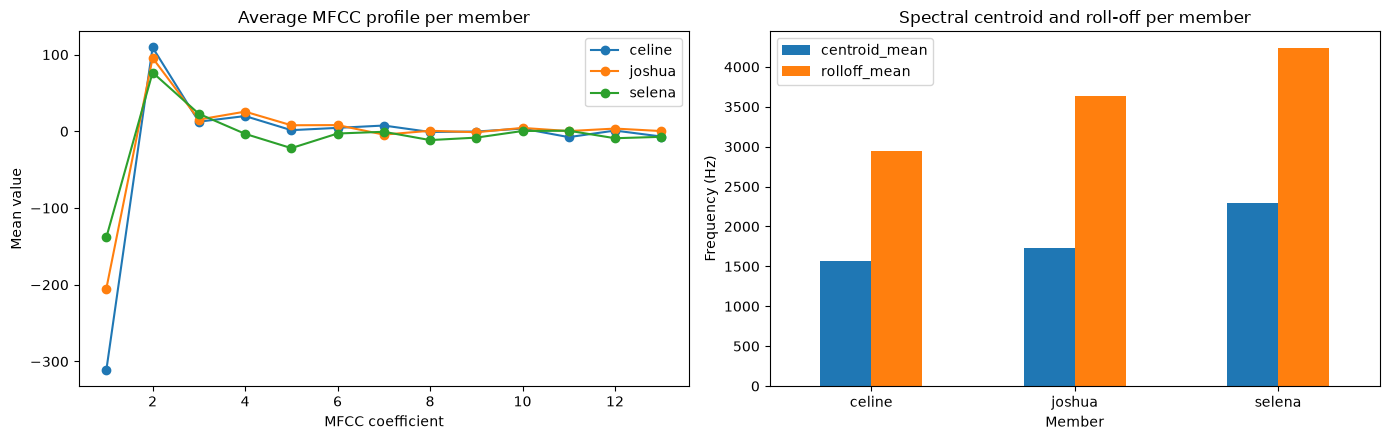

In [36]:
members = sorted(audio_features["member"].unique())
mfcc_cols = [f"mfcc_{i}_mean" for i in range(1, 14)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# left: the average MFCC profile of each member
for m in members:
    axes[0].plot(range(1, 14), audio_features.loc[audio_features["member"] == m, mfcc_cols].mean(), marker="o", label=m)
axes[0].set_xlabel("MFCC coefficient")
axes[0].set_ylabel("Mean value")
axes[0].set_title("Average MFCC profile per member")
axes[0].legend()

# right: brightness and roll-off per member
summary_cols = ["centroid_mean", "rolloff_mean"]
audio_features.groupby("member")[summary_cols].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Spectral centroid and roll-off per member")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_xlabel("Member")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## A7. Train and Evaluate the Voiceprint Model

A normal random split would put augmented copies of the same recording in both the training and the test set. The model would then score well simply because it had seen almost the same clip. Instead we use a **leave-one-phrase-out** test: train on every version of "Yes, approve" and test on "Confirm transaction", then swap. The model has never heard the test phrase from anyone, so a good score means it recognises the speaker, not the recording.

We compare Logistic Regression and a Random Forest, both after scaling the features, and keep the one with the higher F1-score. The final model is then trained on all rows and saved to `models/voice_model.pkl`.

Loaded 36 rows, 34 features, members: ['celine', 'joshua', 'selena']

Leave-one-phrase-out evaluation:
  Logistic Regression  accuracy 0.722   F1 0.720   loss 0.485


  Random Forest        accuracy 0.806   F1 0.810   loss 0.620

Chosen model: Random Forest


Model saved to models\voice_model.pkl


,Accuracy,F1-score,Loss
Logistic Regression,0.722,0.72,0.485
Random Forest,0.806,0.81,0.620


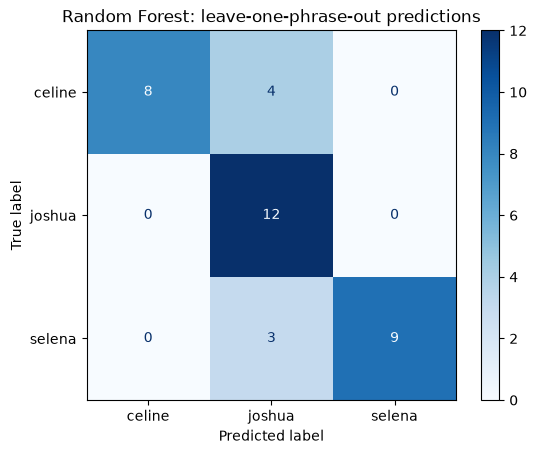

In [37]:
from voice_model import load_features, candidate_models, evaluate, train_and_save
from sklearn.metrics import ConfusionMatrixDisplay

voice_data, voice_cols = load_features()
if voice_data["member"].nunique() < 2:
    print("Only one member's clips are in audio/. Add the other members' clips and rerun this section.")
else:
    results = train_and_save()
    scores = pd.DataFrame({name: {"Accuracy": r["accuracy"], "F1-score": r["f1"], "Loss": r["loss"]}
                           for name, r in results.items()}).T.round(3)
    display(scores)

    best = scores["F1-score"].idxmax()
    ConfusionMatrixDisplay.from_predictions(results[best]["y_true"], results[best]["y_pred"], cmap="Blues")
    plt.title(f"{best}: leave-one-phrase-out predictions")
    plt.show()

**Results:** the Random Forest is chosen, with accuracy 0.81, F1-score 0.81 and loss 0.62 (Logistic Regression: 0.72, 0.72, 0.49). This is lower than with two members, because three voices are harder to tell apart and each member only has two phrases to learn from.

The confusion matrix shows that **every original recording is recognised correctly**. All 7 mistakes are augmented copies of Celine's and Selena's clips that the model calls Joshua, mostly the `noise` copies. This links back to the waveforms: Joshua's real recordings have steady background noise, so the model has partly learned that a noisy clip is probably Joshua. Recording Joshua's phrases again in a quiet room would remove this shortcut and should raise the score.

## A8. Voice Verification and Unauthorized Attempts

In the full system, the face model first says who the person is. The voice step then approves the transaction only if all three checks pass:

1. **Confidence:** the model is at least 60% sure who is speaking.
2. **Distance:** the clip's features are not much further from that member's usual voice than their own recordings are. This catches strangers: a classifier always picks *someone* from the team, even for an unknown voice, so a confidence score alone is not enough.
3. **Agreement:** the voice belongs to the same person as the face. Someone holding up a team member's photo but speaking in their own voice is rejected.

We test this on each member's real clips (should be approved), on each clip paired with the wrong face (should be denied), and on any `unauthorized_*` clips from people outside the team (should be denied).

In [38]:
from voice_model import verify_voice, MODEL_PATH

if not MODEL_PATH.exists():
    print("No voice model saved yet. Run section A7 first.")
else:
    tests = []
    member_clips = list_clips()
    team = sorted({parse_name(p)[0] for p in member_clips})
    for path in member_clips:
        owner, _ = parse_name(path)
        r = verify_voice(path, expected_member=owner)
        tests.append({"clip": path.name, "face_says": owner, "expected": "approve", **r})
        other = next(m for m in team if m != owner)       # same voice, wrong face
        r = verify_voice(path, expected_member=other)
        tests.append({"clip": path.name, "face_says": other, "expected": "deny", **r})
    for path in [p for p in list_clips(include_unauthorized=True) if p not in member_clips]:
        r = verify_voice(path, expected_member=team[0])  # stranger claims to be a team member
        tests.append({"clip": path.name, "face_says": team[0], "expected": "deny", **r})

    test_table = pd.DataFrame(tests)[["clip", "face_says", "expected", "approved", "predicted_member", "confidence", "reason"]]
    test_table["correct"] = (test_table["expected"] == "approve") == test_table["approved"]
    test_table["confidence"] = test_table["confidence"].round(2)
    print(f"{test_table['correct'].sum()} of {len(test_table)} decisions correct")
    display(test_table)

13 of 13 decisions correct


,clip,face_says,expected,approved,predicted_member,confidence,reason,correct
0,Celine_Confirm_transaction.wav,celine,approve,True,celine,0.95,voice matches celine,True
1,Celine_Confirm_transaction.wav,joshua,deny,False,celine,0.95,"voice belongs to celine, but the face was joshua",True
2,celine_yes_approve.wav,celine,approve,True,celine,0.96,voice matches celine,True
3,celine_yes_approve.wav,joshua,deny,False,celine,0.96,"voice belongs to celine, but the face was joshua",True
4,joshua_confirm_transaction.mp4,joshua,approve,True,joshua,0.95,voice matches joshua,True
5,joshua_confirm_transaction.mp4,celine,deny,False,joshua,0.95,"voice belongs to joshua, but the face was celine",True
6,joshua_yes_approve.mp4,joshua,approve,True,joshua,0.92,voice matches joshua,True
7,joshua_yes_approve.mp4,celine,deny,False,joshua,0.92,"voice belongs to joshua, but the face was celine",True
8,selena_confirm_transaction.mp4,selena,approve,True,selena,0.97,voice matches selena,True
9,selena_confirm_transaction.mp4,celine,deny,False,selena,0.97,"voice belongs to selena, but the face was celine",True


**What the voice tests show:** all 13 decisions are correct. Every member's own clips are approved with 92 to 97% confidence. The same clips are denied when the face belongs to someone else, because the voice must match the face. The stranger's clip (`unauthorized_yes_approve.m4a`) is denied because the model is only 38% sure who is speaking, well under the 60% cutoff. Its distance alone would not have caught it, so the confidence check is what does the work here. We have only one stranger recording, so this shows that the check works, not that it is secure against every voice.

**How the three models work together:** the face model answers "who is this?" and unlocks the product model for that member's customer account (Selena = 107, Celine = 113, Joshua = 132). The product prediction is made but kept hidden. The voice model then answers "is it really them, and do they approve?" The prediction is shown only if the voice belongs to the same person as the face. A stranger is stopped at the face step, and someone holding up a member's photo is stopped at the voice step.